# Exploratory Data Analysis
## Basic overview of the images

In [ ]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')

IMAGES_SHAPE = (384, 576)

train_files = list(TRAIN_PATH.glob('*.jpg'))
test_files = list(TEST_PATH.glob('*.jpg'))

train_files_count = len(train_files)
test_files_count = len(test_files)

test_percent = 100 * test_files_count // (test_files_count + train_files_count)

print(f'There are {train_files_count} training images and {test_files_count} '
      f'test images\n\nThis makes a test size of {test_percent}%.')


There are 5546 training images and 3698 test images

This makes a test size of 40%.


## Basic overview of the labels

In [10]:
import pandas as pd

df = pd.read_csv('../data/raw/train.csv')
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Image_Label    22184 non-null  object
 1   EncodedPixels  11836 non-null  object
dtypes: object(2)
memory usage: 346.8+ KB


In [8]:
df.head()

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


## Define an rle_decode function

As I 'found it in the internet':

In [15]:
import numpy as np

def rle_decode(rle_string, shape=(1400, 2100)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle_string, str):
        values = list(map(int, rle_string.split()))
        starts, lengths = values[0::2], values[1::2]
        for start, length in zip(starts, lengths):
            mask[start - 1 : start - 1 + length] = 1  # 1-basiert -> 0-basiert
    return mask.reshape(shape, order="F")  # Fortran-Order = spaltenweise!

## Display the 1st image (as an example)

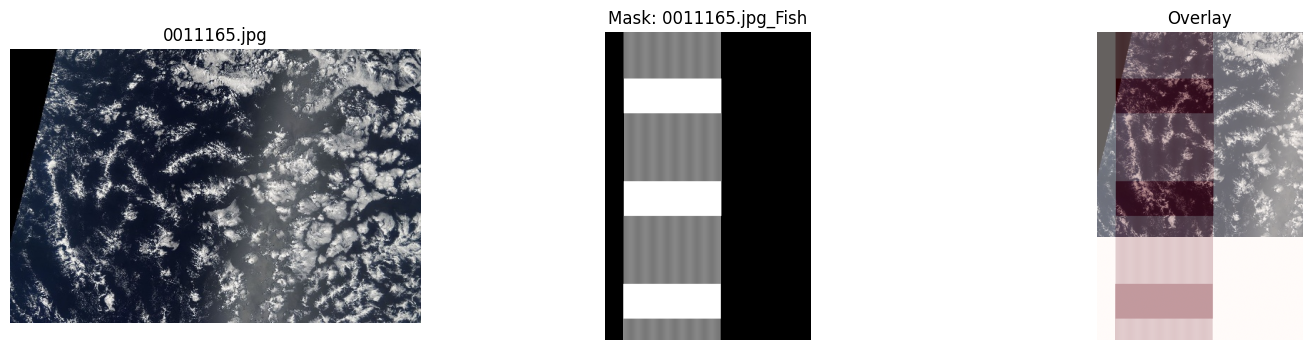

In [16]:
import matplotlib.pyplot as plt

encoded_pixels = df.iloc[0]['EncodedPixels']
decoded_pixels = rle_decode(encoded_pixels, IMAGES_SHAPE)

image_label = df.iloc[0]['Image_Label']
image_id = image_label.split('_')[0]
img = plt.imread(TRAIN_PATH / image_id)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(img)
axes[0].set_title(image_id)
axes[1].imshow(decoded_pixels, cmap='gray')
axes[1].set_title(f'Mask: {image_label}')
axes[2].imshow(img)
axes[2].imshow(decoded_pixels, cmap='Reds', alpha=0.4)  # transparent overlay
axes[2].set_title('Overlay')
for ax in axes:
    ax.axis('off')
plt.show()
